# Revised model development with a fixed validation set

This notebook develops LightGBM regression models using the selected feature set from `feature_engineering.ipynb` for the split named by `SPLIT_SCHEME`. Hyperparameters are optimized with `BayesSearchCV` using one predefined train/validation split. The test set is not loaded or used in this notebook.

Separate models are developed for the low-MP (`L`), high-MP (`H`), and all-compound (`All`) regimes. `TRAINING_VARIANT` selects the development tables: `'full'`, the full training and validation sets, or `'balanced'`, the balanced Low+High subsets of both (`balanced_train.csv` and `balanced_validation.csv`, defined in `1_data_split/data_split.ipynb`), so that the balanced run is balanced in both hyperparameter search and final refit. Models are saved to `models/<SPLIT_SCHEME>/<TRAINING_VARIANT>/`. The final refit mode is configurable and can use either training data only or training plus validation data after model decisions are frozen.

In [1]:
from pathlib import Path
import json
import pickle
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import PredefinedSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb
from skopt import BayesSearchCV
from skopt.space import Real, Integer

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / '0_data' / 'outputs' / 'combined_data.parquet').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / '0_data' / 'outputs' / 'combined_data.parquet').is_file():
    raise FileNotFoundError('Run this notebook from the repository root or a project subdirectory.')

SPLIT_SCHEME = 'stereo_cleaned'  # folder written by 1_data_split/data_split.ipynb
TRAINING_VARIANT = 'balanced'  # 'full' or 'balanced'; also the name of the model folder
FEATURE_ROOT = PROJECT_ROOT / '2_feature_engineering' / 'outputs' / SPLIT_SCHEME
SELECTED_DIR = FEATURE_ROOT / 'selected_features'
FEATURE_LIST_PATH = FEATURE_ROOT / 'selected_features.csv'
TRAIN_FILENAME = 'train_selected_features.parquet'
VALIDATION_FILENAME = 'validation_selected_features.parquet'

if TRAINING_VARIANT == 'balanced':
    # The full training table, restricted to the balanced compound list from data_split.ipynb.
    TRAIN_PATH = SELECTED_DIR / TRAIN_FILENAME
    BALANCED_TRAIN_LIST_PATH = PROJECT_ROOT / '1_data_split' / 'outputs' / SPLIT_SCHEME / 'balanced_train.csv'
    # The full validation table, restricted to the balanced validation list from data_split.ipynb.
    VALIDATION_PATH = SELECTED_DIR / VALIDATION_FILENAME
    BALANCED_VALIDATION_LIST_PATH = PROJECT_ROOT / '1_data_split' / 'outputs' / SPLIT_SCHEME / 'balanced_validation.csv'
    DATA_TYPES = ['L', 'H', 'All']
elif TRAINING_VARIANT == 'full':
    TRAIN_PATH = SELECTED_DIR / TRAIN_FILENAME
    VALIDATION_PATH = SELECTED_DIR / VALIDATION_FILENAME
    DATA_TYPES = ['L', 'H', 'All']
else:
    raise ValueError(f'Unsupported TRAINING_VARIANT: {TRAINING_VARIANT}')
MODEL_OUTPUT_DIR = PROJECT_ROOT / '3_model_development' / 'models' / SPLIT_SCHEME / TRAINING_VARIANT
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RUN_ID = pd.Timestamp.now().strftime('%Y%m%d_%H%M%S')
HPO_OUTPUT_DIR = MODEL_OUTPUT_DIR / 'hyperparameter_optimization' / RUN_ID
HPO_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_TYPES = ['LGB']
MP_COLUMN = 'MP'
CLASS_COLUMN = 'MP_class'
RANDOM_STATE = 2026
N_BAYES_TRIALS = 20
FINAL_FIT_MODE = 'train_plus_validation'

print('Split scheme:', SPLIT_SCHEME)
print('Training variant:', TRAINING_VARIANT)
print('Training input:', TRAIN_PATH.relative_to(PROJECT_ROOT))
print('Validation input:', VALIDATION_PATH.relative_to(PROJECT_ROOT))
print('Model output directory:', MODEL_OUTPUT_DIR.relative_to(PROJECT_ROOT))
print('HPO archive directory:', HPO_OUTPUT_DIR.relative_to(PROJECT_ROOT))
print('Model types:', MODEL_TYPES)
print('Data regimes:', DATA_TYPES)

Split scheme: stereo_cleaned
Training variant: balanced
Training input: 2_feature_engineering/outputs/stereo_cleaned/selected_features/train_selected_features.parquet
Validation input: 2_feature_engineering/outputs/stereo_cleaned/selected_features/validation_selected_features.parquet
Model output directory: 3_model_development/models/stereo_cleaned/balanced
HPO archive directory: 3_model_development/models/stereo_cleaned/balanced/hyperparameter_optimization/20261120_042119
Model types: ['LGB']
Data regimes: ['L', 'H', 'All']


## Load the selected features

Only the train and validation tables are loaded. The feature list is used explicitly so metadata cannot accidentally enter the model matrix.

In [2]:
if not FEATURE_LIST_PATH.is_file():
    raise FileNotFoundError(f'Missing selected feature list: {FEATURE_LIST_PATH}')

feature_names = pd.read_csv(FEATURE_LIST_PATH)['Feature'].dropna().astype(str).tolist()
def restrict_to_list(frame, list_path, split_name):
    # Keep the listed compounds, in the order of the list written by data_split.ipynb.
    listed_smiles = pd.read_csv(list_path)['SMILES']
    row_of = pd.Series(np.arange(len(frame)), index=frame['SMILES'])
    missing_smiles = listed_smiles[~listed_smiles.isin(row_of.index)]
    if len(missing_smiles):
        raise ValueError(f'{len(missing_smiles):,} balanced {split_name} compounds are missing from the {split_name} features.')
    return frame.iloc[row_of.loc[listed_smiles].to_numpy()].reset_index(drop=True)

train_data = pd.read_parquet(TRAIN_PATH)
validation_data = pd.read_parquet(VALIDATION_PATH)
if TRAINING_VARIANT == 'balanced':
    train_data = restrict_to_list(train_data, BALANCED_TRAIN_LIST_PATH, 'training')
    validation_data = restrict_to_list(validation_data, BALANCED_VALIDATION_LIST_PATH, 'validation')

required_metadata = {MP_COLUMN, CLASS_COLUMN}
for split_name, frame in {'train': train_data, 'validation': validation_data}.items():
    missing_features = sorted(set(feature_names).difference(frame.columns))
    missing_metadata = sorted(required_metadata.difference(frame.columns))
    if missing_features or missing_metadata:
        raise ValueError(f'{split_name}: missing features={missing_features[:5]}, missing metadata={missing_metadata}')
    if frame[feature_names].isna().any().any():
        raise ValueError(f'{split_name} contains NaN values in selected features.')

print('Train shape:', train_data.shape)
print('Validation shape:', validation_data.shape)
print('Selected features:', len(feature_names))
display(pd.DataFrame({'train': train_data[CLASS_COLUMN].value_counts(), 'validation': validation_data[CLASS_COLUMN].value_counts()}).rename_axis(CLASS_COLUMN))

def regime_mask(frame, regime):
    if regime == 'All':
        return pd.Series(True, index=frame.index)
    target = {'L': 'low', 'H': 'high'}.get(regime)
    if target is None:
        raise ValueError(f'Unsupported regime: {regime}')
    normalized = frame[CLASS_COLUMN].astype(str).str.strip().str.lower()
    return normalized.eq(target)

Train shape: (25692, 1711)
Validation shape: (8564, 1711)
Selected features: 1690


,train,validation
MP_class,,
low,12846,4282
high,12846,4282


## Model definition and fixed-validation Bayesian search

`PredefinedSplit` marks training rows with `-1` and validation rows with `0`. Consequently, every `BayesSearchCV` trial is fitted on the training subset and evaluated once on the same fixed validation subset. This is not 10-fold cross-validation.

The LightGBM search space (parameters, ranges and priors) and the number of Bayesian trials are the same as in the original `model_development.ipynb`, so the original and revised workflows are tuned identically. As in the original, `subsample_freq` is left at its default of 0, so the sampled `subsample` value does not change the fitted model.

In [3]:
def model_definition(model_type):
    if model_type == 'LGB':
        estimator = lgb.LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1)
        search_space = {
            'num_leaves': Integer(20, 300),
            'max_depth': Integer(3, 12),
            'learning_rate': Real(0.01, 0.3, prior='log-uniform'),
            'n_estimators': Integer(20, 500),
            'min_child_samples': Integer(10, 50),
            'subsample': Real(0.6, 1.0),
            'colsample_bytree': Real(0.4, 1.0),
            'reg_alpha': Real(1e-5, 10.0, prior='log-uniform'),
            'reg_lambda': Real(1e-5, 10.0, prior='log-uniform'),
        }
    else:
        raise ValueError(f'Unsupported model type: {model_type}')
    return estimator, search_space

def native_params(params):
    # BayesSearchCV returns numpy scalars; store plain Python numbers.
    return {str(key): value.item() if hasattr(value, 'item') else value for key, value in params.items()}

def make_regression_metrics(y_true, prediction):
    return {
        'RMSE': float(np.sqrt(mean_squared_error(y_true, prediction))),
        'MAE': float(mean_absolute_error(y_true, prediction)),
        'R2': float(r2_score(y_true, prediction)),
    }

def fixed_validation_search(train_subset, validation_subset, model_type):
    X_train = train_subset[feature_names]
    y_train = train_subset[MP_COLUMN].to_numpy()
    X_validation = validation_subset[feature_names]
    y_validation = validation_subset[MP_COLUMN].to_numpy()

    X_search = pd.concat([X_train, X_validation], ignore_index=True)
    y_search = np.concatenate([y_train, y_validation])
    test_fold = np.concatenate([
        np.full(len(X_train), -1, dtype=int),
        np.zeros(len(X_validation), dtype=int),
    ])
    fixed_split = PredefinedSplit(test_fold=test_fold)

    default_model, search_space = model_definition(model_type)
    default_model.fit(X_train, y_train)
    default_metrics = make_regression_metrics(y_validation, default_model.predict(X_validation))

    optimizer_model, _ = model_definition(model_type)
    search = BayesSearchCV(
        estimator=optimizer_model,
        search_spaces=search_space,
        n_iter=N_BAYES_TRIALS,
        cv=fixed_split,
        scoring='neg_root_mean_squared_error',
        random_state=RANDOM_STATE,
        n_jobs=1,
        refit=False,
    )
    search.fit(X_search, y_search)

    trial_rows = []
    for trial_index, (params, score) in enumerate(zip(search.cv_results_['params'], search.cv_results_['split0_test_score'])):
        trial_rows.append({
            'Trial': trial_index + 1,
            'Validation_RMSE': float(-score),
            'Parameters': json.dumps(native_params(params), sort_keys=True),
        })
    trial_results = pd.DataFrame(trial_rows).sort_values('Validation_RMSE').reset_index(drop=True)
    best_params = native_params(search.best_params_)

    return {
        'default_metrics': default_metrics,
        'trial_results': trial_results,
        'best_params': best_params,
    }

## Run model development for `L`, `H`, and `All`

The `L` and `H` models are useful for regime-specific analysis. The `All` model is the general-purpose regression model. Because the true MP class is unavailable for an unknown compound, using the `L`/`H` models for deployment would require a separate routing classifier.

In [4]:
all_results = {}

for model_type in MODEL_TYPES:
    for data_type in DATA_TYPES:
        train_subset = train_data.loc[regime_mask(train_data, data_type)].reset_index(drop=True)
        validation_subset = validation_data.loc[regime_mask(validation_data, data_type)].reset_index(drop=True)

        if len(train_subset) < 10 or len(validation_subset) < 5:
            raise ValueError(f'{data_type} subset is too small: train={len(train_subset)}, validation={len(validation_subset)}')

        key = f'{model_type}_{data_type}'
        print(f'\n=== {key} ===')
        print(f'Train compounds: {len(train_subset):,}; validation compounds: {len(validation_subset):,}')
        result = fixed_validation_search(train_subset, validation_subset, model_type)
        all_results[key] = result

        result['trial_results'].to_csv(MODEL_OUTPUT_DIR / f'trial_results_{key}.csv', index=False)
        (MODEL_OUTPUT_DIR / f'best_params_{key}.json').write_text(json.dumps(result['best_params'], indent=2))
        with open(MODEL_OUTPUT_DIR / f'development_summary_{key}.pkl', 'wb') as handle:
            pickle.dump({'default_metrics': result['default_metrics'], 'best_params': result['best_params'], 'best_validation_row': result['trial_results'].iloc[0].to_dict()}, handle)

        # Archive every HPO run separately so later notebook runs do not erase history.
        result['trial_results'].to_csv(HPO_OUTPUT_DIR / f'trial_results_{key}.csv', index=False)
        (HPO_OUTPUT_DIR / f'best_params_{key}.json').write_text(json.dumps(result['best_params'], indent=2))
        hpo_summary = {
            'run_id': RUN_ID,
            'split_scheme': SPLIT_SCHEME,
            'training_variant': TRAINING_VARIANT,
            'model_type': model_type,
            'data_regime': data_type,
            'n_bayes_trials': N_BAYES_TRIALS,
            'train_compounds': len(train_subset),
            'validation_compounds': len(validation_subset),
            'default_validation_metrics': result['default_metrics'],
            'best_params': result['best_params'],
            'best_validation_row': result['trial_results'].iloc[0].to_dict(),
        }
        (HPO_OUTPUT_DIR / f'hpo_summary_{key}.json').write_text(json.dumps(hpo_summary, indent=2, default=str))
        summary_text = [
            f'=== {key} ===',
            f'Train compounds: {len(train_subset):,}; validation compounds: {len(validation_subset):,}',
            f'Default validation metrics: {result["default_metrics"]}',
            f'Best parameters: {result["best_params"]}',
            '',
            'Best Bayesian-search row:',
            result['trial_results'].head(1).to_string(index=False),
        ]
        (HPO_OUTPUT_DIR / f'hpo_summary_{key}.txt').write_text('\n'.join(summary_text))

        print('Default validation metrics:', result['default_metrics'])
        print('Best parameters:', result['best_params'])
        print('Best Bayesian-search row:')
        display(result['trial_results'].head(1))


=== LGB_L ===
Train compounds: 12,846; validation compounds: 4,282


Default validation metrics: {'RMSE': 37.70382796266908, 'MAE': 29.721763816763737, 'R2': 0.49134750860195797}
Best parameters: {'colsample_bytree': 0.9544028063936459, 'learning_rate': 0.04130880678838867, 'max_depth': 9, 'min_child_samples': 48, 'n_estimators': 500, 'num_leaves': 47, 'reg_alpha': 0.3544333783364519, 'reg_lambda': 10.0, 'subsample': 0.9683941953971005}
Best Bayesian-search row:


,Trial,Validation_RMSE,Parameters
0,19,37.096631,"{""colsample_bytree"": 0.9544028063936459, ""lear..."



=== LGB_H ===
Train compounds: 12,846; validation compounds: 4,282


Default validation metrics: {'RMSE': 23.122715017642086, 'MAE': 17.687740067248228, 'R2': 0.22683309547275832}
Best parameters: {'colsample_bytree': 0.7363796353366491, 'learning_rate': 0.022731314142612313, 'max_depth': 12, 'min_child_samples': 50, 'n_estimators': 500, 'num_leaves': 291, 'reg_alpha': 0.7653007582806595, 'reg_lambda': 0.25814379833700807, 'subsample': 0.9811640699533658}
Best Bayesian-search row:


,Trial,Validation_RMSE,Parameters
0,14,22.677822,"{""colsample_bytree"": 0.7363796353366491, ""lear..."



=== LGB_All ===
Train compounds: 25,692; validation compounds: 8,564


Default validation metrics: {'RMSE': 47.032661834821894, 'MAE': 35.511048015259064, 'R2': 0.6534876455900305}
Best parameters: {'colsample_bytree': 0.4, 'learning_rate': 0.03715448581221392, 'max_depth': 9, 'min_child_samples': 12, 'n_estimators': 500, 'num_leaves': 157, 'reg_alpha': 1e-05, 'reg_lambda': 0.7716285755240028, 'subsample': 0.8867217185321263}
Best Bayesian-search row:


,Trial,Validation_RMSE,Parameters
0,17,44.855835,"{""colsample_bytree"": 0.4, ""learning_rate"": 0.0..."


Saved hyperparameter-search figure to 3_model_development/models/stereo_cleaned/balanced/hyperparameter_optimization/20261120_042119/hyperparameter_search_LGB_L.png


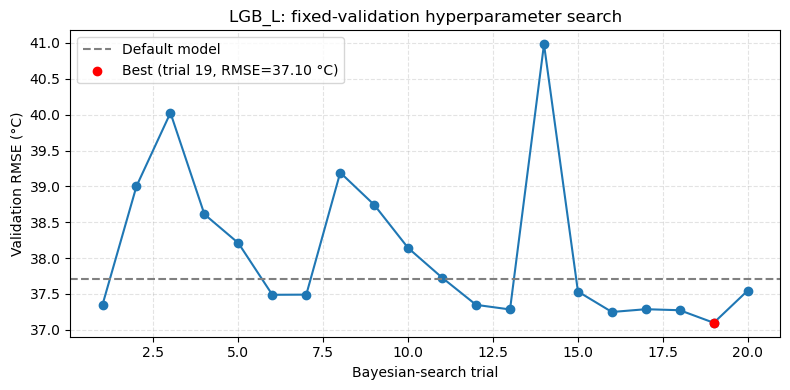

Saved hyperparameter-search figure to 3_model_development/models/stereo_cleaned/balanced/hyperparameter_optimization/20261120_042119/hyperparameter_search_LGB_H.png


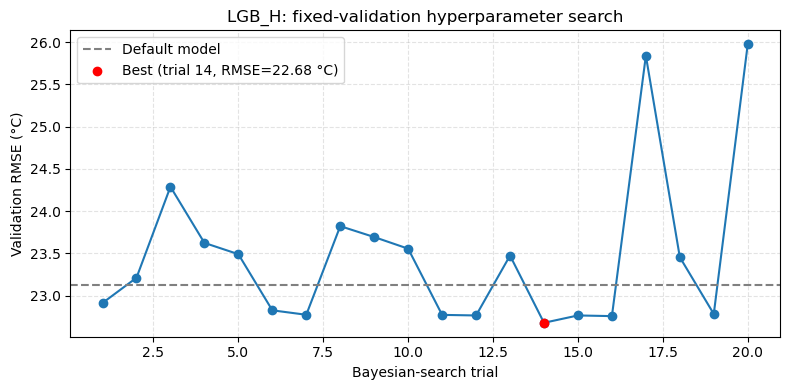

Saved hyperparameter-search figure to 3_model_development/models/stereo_cleaned/balanced/hyperparameter_optimization/20261120_042119/hyperparameter_search_LGB_All.png


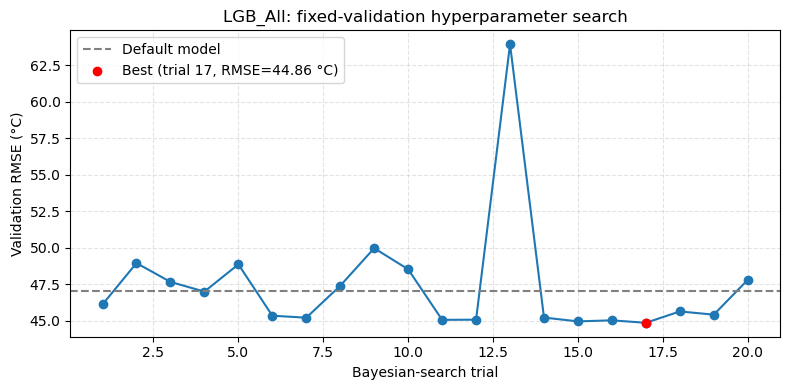

In [5]:
import matplotlib.pyplot as plt

for key, result in all_results.items():
    trials = result['trial_results'].sort_values('Trial')
    plt.figure(figsize=(8, 4))
    plt.plot(trials['Trial'], trials['Validation_RMSE'], marker='o')
    plt.axhline(result['default_metrics']['RMSE'], color='grey', linestyle='--', label='Default model')
    best = result['trial_results'].iloc[0]
    plt.scatter([best['Trial']], [best['Validation_RMSE']], color='red', zorder=5,
                label=f"Best (trial {int(best['Trial'])}, RMSE={best['Validation_RMSE']:.2f} °C)")
    plt.xlabel('Bayesian-search trial')
    plt.ylabel('Validation RMSE (°C)')
    plt.title(f'{key}: fixed-validation hyperparameter search')
    plt.grid(True, linestyle='--', alpha=0.35)
    plt.legend()
    plt.tight_layout()
    figure_path = HPO_OUTPUT_DIR / f'hyperparameter_search_{key}.png'
    plt.savefig(figure_path, dpi=200, bbox_inches='tight')
    print(f'Saved hyperparameter-search figure to {figure_path.relative_to(PROJECT_ROOT)}')
    plt.show()

## Fit and save the final models

After fixed-validation hyperparameter selection, each model is refit with its selected hyperparameters according to `FINAL_FIT_MODE`. With `train_plus_validation`, the training rows of the regime are combined with the regime's validation rows. The test set is not loaded or used here.

For the `balanced` variant, both tables are the balanced subsets, so the final model is refit on the balanced training table plus the balanced validation table of the regime: the Low-MP model (`L`) on as many Low-MP compounds as the High-MP model, and the all-compound model (`All`) on a 50:50 Low/High set. The saved metadata records the number of training and validation rows used.

In [6]:
final_models = {}
for key, result in all_results.items():
    model_type, data_type = key.rsplit('_', 1)
    train_subset = train_data.loc[regime_mask(train_data, data_type)].reset_index(drop=True)
    validation_subset = validation_data.loc[regime_mask(validation_data, data_type)].reset_index(drop=True)
    if FINAL_FIT_MODE == 'train_plus_validation':
        fit_data = pd.concat([train_subset, validation_subset], ignore_index=True)
    elif FINAL_FIT_MODE == 'train_only':
        fit_data = train_subset
    else:
        raise ValueError(f'Unsupported FINAL_FIT_MODE: {FINAL_FIT_MODE}')
    final_model, _ = model_definition(model_type)
    final_model.set_params(**result['best_params'])
    final_model.fit(fit_data[feature_names], fit_data[MP_COLUMN].to_numpy())
    model_path = MODEL_OUTPUT_DIR / f'best_model_{key}_{FINAL_FIT_MODE}.joblib'
    joblib.dump(final_model, model_path, compress=3)
    metadata = {
        'split_scheme': SPLIT_SCHEME,
        'training_variant': TRAINING_VARIANT,
        'model_type': model_type,
        'data_regime': data_type,
        'final_fit_mode': FINAL_FIT_MODE,
        'train_rows_used': int(len(train_subset)),
        'validation_rows_used': int(len(validation_subset)),
        'final_fit_rows': int(len(fit_data)),
        'selected_feature_count': int(len(feature_names)),
        'random_state': RANDOM_STATE,
        'test_used': False,
    }
    (MODEL_OUTPUT_DIR / f'model_metadata_{key}_{FINAL_FIT_MODE}.json').write_text(json.dumps(metadata, indent=2))
    final_models[key] = final_model
    print(f'Saved {key}: {model_path.relative_to(PROJECT_ROOT)}')
    print(f'  final-fit rows: {len(fit_data):,} (train={len(train_subset):,}, validation={len(validation_subset):,})')

Saved LGB_L: 3_model_development/models/stereo_cleaned/balanced/best_model_LGB_L_train_plus_validation.joblib
  final-fit rows: 17,128 (train=12,846, validation=4,282)


Saved LGB_H: 3_model_development/models/stereo_cleaned/balanced/best_model_LGB_H_train_plus_validation.joblib
  final-fit rows: 17,128 (train=12,846, validation=4,282)


Saved LGB_All: 3_model_development/models/stereo_cleaned/balanced/best_model_LGB_All_train_plus_validation.joblib
  final-fit rows: 34,256 (train=25,692, validation=8,564)
